Récupération des données via Yahoo Finance

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# 1. Sous-jacent et spot
ticker_symbol = "^SPX"  # Astuce : si ^SPX est vide ou buggé sur Yahoo, teste avec "SPY"
spx = yf.Ticker(ticker_symbol)~~~~

hist = spx.history(period="1d")
spot = hist["Close"].iloc[-1]
today = pd.Timestamp.today().normalize()

print(f"Spot {ticker_symbol} : {spot:.2f}")

# 2. Récupération de toutes les maturités
records = []
expirations = spx.options

for exp in expirations:
    t_exp = pd.to_datetime(exp)
    ttm = (t_exp - today).days / 365.0  # Time to maturity en années

    # On écarte les 0DTE (< 7j) trop instables et les maturités > 2 ans trop illiquides
    if ttm < 7 / 365.0 or ttm > 2.0:
        continue

    chain = spx.option_chain(exp)
    c = chain.calls.copy()
    p = chain.puts.copy()

    c["type"] = "call"
    p["type"] = "put"
    c["T"] = ttm
    p["T"] = ttm

    records.append(c)
    records.append(p)

raw_options = pd.concat(records, ignore_index=True)
print(f"Nombre total de contrats bruts récupérés : {len(raw_options)}")

Spot ^SPX : 7656.98
Nombre total de contrats bruts récupérés : 14697


Inversion BS et filtrage (on garde que les options OTM car full liquidité)

In [2]:
from scipy.stats import norm
from scipy.optimize import brentq

# 1. Base et mid price
df = raw_options.copy()
df["mid"] = (df["bid"] + df["ask"]) / 2

# 2. Filtres de liquidité préalables
df = df[
    (df["mid"] > 0.05) &
    (df["bid"] > 0) &
    (df["ask"] >= df["bid"])
].copy()

# 3. Séparation OTM (Calls si K >= Spot, Puts si K < Spot)
otm_puts = df[(df["type"] == "put") & (df["strike"] < spot)]
otm_calls = df[(df["type"] == "call") & (df["strike"] >= spot)]
df_otm = pd.concat([otm_puts, otm_calls], ignore_index=True)

# 4. Taux proxy et forward F = S * exp(r*T)
r = 0.045
df_otm["F"] = spot * np.exp(r * df_otm["T"])
df_otm["k"] = np.log(df_otm["strike"] / df_otm["F"])

# 5. Moteur d'inversion Black-Scholes
def bs_price(S, K, T, r, sigma, opt_type):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if opt_type == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def invert_iv(row):
    price = row["mid"]
    S = spot
    K = row["strike"]
    T = row["T"]
    opt_type = row["type"]

    intrinsic = max(0.0, S - K * np.exp(-r * T)) if opt_type == "call" else max(0.0, K * np.exp(-r * T) - S)
    if price <= intrinsic:
        return np.nan

    def obj(sigma):
        return bs_price(S, K, T, r, sigma, opt_type) - price

    try:
        return brentq(obj, 1e-4, 3.0, maxiter=100)
    except (ValueError, RuntimeError):
        return np.nan

# 6. Inversion numérique
df_otm["iv_custom"] = df_otm.apply(invert_iv, axis=1)

# 7. Nettoyage et variance totale
df_otm = df_otm.dropna(subset=["iv_custom"]).copy()
df_otm["total_var"] = (df_otm["iv_custom"] ** 2) * df_otm["T"]

# 8. Filtre des maturités avec assez de points
valid_expirations = df_otm.groupby("T").filter(lambda x: len(x) >= 6)

print(f"Maturités exploitables : {valid_expirations['T'].nunique()}")
print(f"Options OTM retenues : {len(valid_expirations)}")

Maturités exploitables : 42
Options OTM retenues : 8724


S(S)VI (Surface Stochastic Volatility Inspired) --> pour interpoler
Extrait la variance totale ATM $\theta_T$, calibre les trois paramètres globaux $\rho, \eta, \gamma$ et stocke les variables réutilisables.

In [4]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Extraction et monotonisation de la variance totale ATM theta_T
atm_records = []
for T_val, grp in valid_expirations.groupby("T"):
    atm_row = grp.iloc[(grp["k"].abs()).argmin()]
    atm_records.append({"T": T_val, "theta": atm_row["total_var"]})

atm_df = pd.DataFrame(atm_records).sort_values("T")

# Monotonie stricte pour éliminer l'arbitrage calendrier ATM
atm_df["theta"] = np.maximum.accumulate(atm_df["theta"])

# Jointure pour injecter theta_T
df_ssvi = valid_expirations.merge(atm_df, on="T")

# 2. Formulation analytique SSVI régularisée à l'origine
# L'ajout de eps évite l'explosion de phi en 1/theta^gamma quand theta -> 0
def phi_power(theta, eta, gamma, eps=0.008):
    return eta / ((theta + eps) ** gamma)

def ssvi_total_variance(k, theta, rho, eta, gamma):
    phi = phi_power(theta, eta, gamma)
    z = phi * k
    inside_sqrt = (z + rho)**2 + (1.0 - rho**2)
    return 0.5 * theta * (1.0 + rho * z + np.sqrt(inside_sqrt))

def ssvi_loss(params, k_arr, theta_arr, target_w):
    rho, eta, gamma = params

    # Condition stricte d'absence d'arbitrage papillon
    if eta * (1.0 + abs(rho)) > 2.0:
        return 1e9

    w_model = ssvi_total_variance(k_arr, theta_arr, rho, eta, gamma)
    return np.mean((w_model - target_w)**2)

# 3. Optimisation bornée avec L-BFGS-B
k_data = df_ssvi["k"].values
theta_data = df_ssvi["theta"].values
w_data = df_ssvi["total_var"].values

bounds = [
    (-0.95, -0.05),  # rho négatif (skew equity standard)
    (0.01, 2.00),    # eta > 0
    (0.01, 0.70)     # gamma
]

p0 = [-0.50, 1.00, 0.60]

res = minimize(
    ssvi_loss,
    p0,
    args=(k_data, theta_data, w_data),
    method="L-BFGS-B",
    bounds=bounds
)

rho_opt, eta_opt, gamma_opt = res.x

print("=== Paramètres SSVI calibrés (régularisés) ===")
print(f"rho   : {rho_opt:.4f}")
print(f"eta   : {eta_opt:.4f}")
print(f"gamma : {gamma_opt:.4f}")
print(f"Contrainte papillon : {eta_opt * (1 + abs(rho_opt)):.3f} <= 2.0")

=== Paramètres SSVI calibrés (régularisés) ===
rho   : -0.5253
eta   : 1.0432
gamma : 0.7000
Contrainte papillon : 1.591 <= 2.0


Nappe de vol

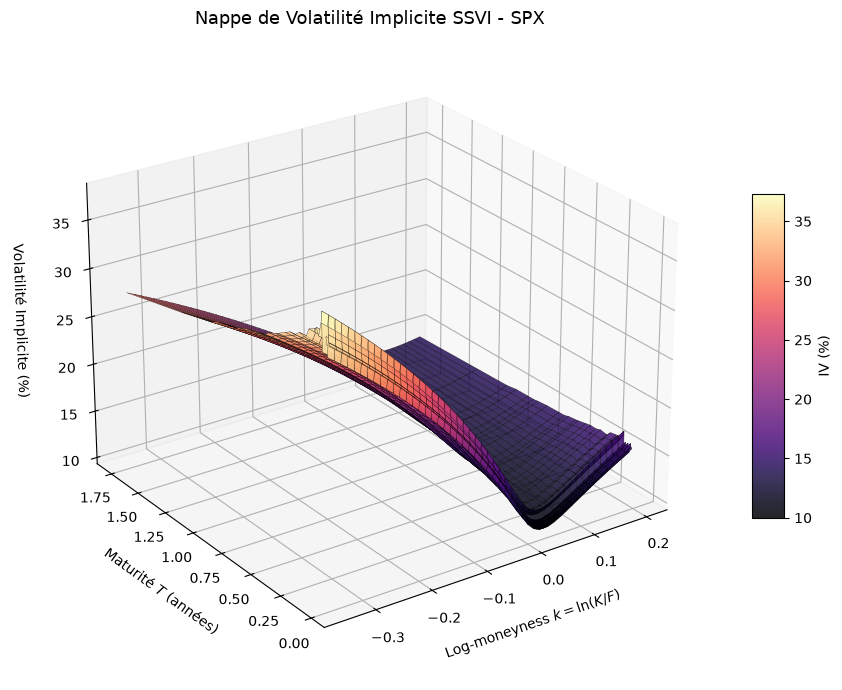

In [5]:
import matplotlib.pyplot as plt

# 1. Grille d'évaluation régulière
maturities = atm_df["T"].values
thetas = atm_df["theta"].values
k_grid = np.linspace(-0.35, 0.20, 50)

K_mesh, T_mesh = np.meshgrid(k_grid, maturities)
IV_surface = np.zeros_like(K_mesh)

# 2. Évaluation de la vol implicite via les paramètres calibrés
for i, (T_val, th_val) in enumerate(zip(maturities, thetas)):
    w_pred = ssvi_total_variance(k_grid, th_val, rho_opt, eta_opt, gamma_opt)
    IV_surface[i, :] = np.sqrt(np.maximum(w_pred, 1e-6) / T_val)

# 3. Tracé 3D
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    K_mesh,
    T_mesh,
    IV_surface * 100,
    cmap="magma",
    edgecolor="k",
    linewidth=0.2,
    alpha=0.85
)

ax.set_title("Nappe de Volatilité Implicite SSVI - SPX", fontsize=13)
ax.set_xlabel(r"Log-moneyness $k = \ln(K/F)$", labelpad=10)
ax.set_ylabel(r"Maturité $T$ (années)", labelpad=10)
ax.set_zlabel("Volatilité Implicite (%)", labelpad=10)
ax.view_init(elev=25, azim=-125)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label="IV (%)")
plt.tight_layout()
plt.show()

In [7]:
import plotly.graph_objects as go

# Construction de la nappe
fig = go.Figure(data=[
    go.Surface(
        x=k_grid,
        y=maturities,
        z=IV_surface * 100,
        colorscale="Magma",
        colorbar=dict(title="IV (%)")
    )
])

fig.update_layout(
    title="Nappe de Volatilité Implicite SSVI - SPX",
    scene=dict(
        xaxis_title="Log-moneyness k = ln(K/F)",
        yaxis_title="Maturité T (années)",
        zaxis_title="Volatilité Implicite (%)"
    ),
    width=900,
    height=600
)

# Génère la page HTML et l'ouvre directement dans ton navigateur
fig.write_html("nappe_ssvi.html", auto_open=True)